Exercice 2 : Réseau de neurones sur Iris

Etape 1 : Importer les librairies

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

tf.keras.utils.set_random_seed(42)  # Pour la reproductibilité des résultats

Etape 2 : Charger le dataset Iris

In [3]:
iris = load_iris()
X = iris.data       # 4 features
y = iris.target     # classes 0,1,2

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (150, 4)
Dimensions de y : (150,)


Etape 3 : Visualiser les 5 premières lignes

In [4]:
print("Exemples de X :\n", X[:5])
print("Exemples de y :\n", y[:5])

Exemples de X :
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
Exemples de y :
 [0 0 0 0 0]


Etape 4 : Split train/test

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Taille train :", X_train.shape)
print("Taille test :", X_test.shape)

Taille train : (120, 4)
Taille test : (30, 4)


Etape 5 : One-Hot Encoding pour les sorties

In [23]:
encoder = OneHotEncoder(sparse_output=False)
y_train = encoder.fit_transform(y_train.reshape(-1, 1))
y_test = encoder.transform(y_test.reshape(-1, 1))
print("Exemples de y_train après OneHotEncoding :\n", y_train[:5])

Exemples de y_train après OneHotEncoding :
 [[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


Etape 6 : Normaliser les features

In [24]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Exemples de X_train après StandardScaler :\n", X_train[:5])

Exemples de X_train après StandardScaler :
 [[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


Etape 7 : Construire le modèle MLP

In [12]:
model = Sequential([
    Input(shape=(4,)),  # 4 features
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')  # 3 classes
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

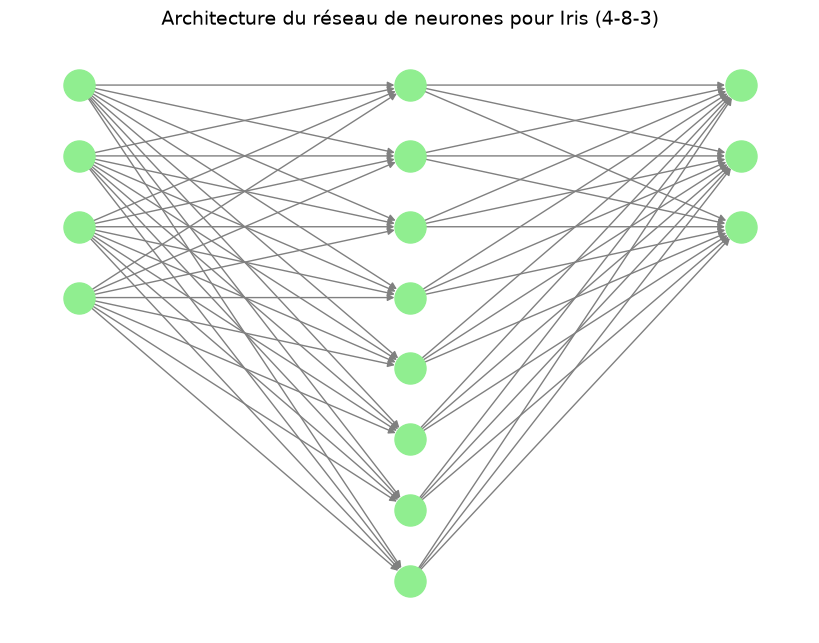

In [14]:
layers = [4, 8, 3]  # Input layer: 4 neurons, Hidden layer: 8 neurons, Output layer: 3 neurons

G = nx.DiGraph()
pos = {}
layer_positions = []

for l, n_neurons in enumerate(layers):
    layer_pos = []
    for n in range(n_neurons):
        node_id = f"L{l}N{n}"
        G.add_node(node_id, layer=l)
        pos[node_id] = (l, -n)  # Positionnement des neurones dans le graphe
        layer_pos.append(node_id)
    layer_positions.append(layer_pos)

for l in range(len(layers) - 1):
    for src in layer_positions[l]:
        for dst in layer_positions[l + 1]:
            G.add_edge(src, dst)

plt.figure(figsize=(8, 6))
nx.draw(G, pos, with_labels=False, node_size=500, node_color='lightgreen', edge_color='gray')
plt.title("Architecture du réseau de neurones pour Iris (4-8-3)", fontsize=14)
plt.show()

Etape 8 : Compiler le modèle

In [16]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

Etape 9 : Entraîner le modèle

In [17]:
history = model.fit(X_train, y_train, epochs=100, batch_size=5, validation_split=0.1, verbose=1)

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6667 - loss: 0.8413 - val_accuracy: 0.6667 - val_loss: 0.8729
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7130 - loss: 0.7885 - val_accuracy: 0.6667 - val_loss: 0.8193
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7037 - loss: 0.7399 - val_accuracy: 0.6667 - val_loss: 0.7700
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7130 - loss: 0.6957 - val_accuracy: 0.6667 - val_loss: 0.7271
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7315 - loss: 0.6556 - val_accuracy: 0.6667 - val_loss: 0.6902
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7593 - loss: 0.6201 - val_accuracy: 0.6667 - val_loss: 0.6591
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7778 - loss: 0.5893 - val_accuracy: 0.6667 - val_loss: 0.6335
Epoch 8/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7778 - loss: 0.5630 - val_accuracy: 0.6667 - 

- epoch : nombre de fois où le modèle traite l'ensemble des données d'entraînement
- batch_size : nombre d'exemples traités avant de corriger les poids et le biais
- validation_split : pourcentage des données d'apprentissage réservé à la vérification à la fin de chaque epoch,
elles ne servent pas au calcul des poids et du biais
- accuracy = nbre de prédictions correctes / nbre total de prédictions
- loss = mesure de l'écart entre la valeur obtenue et la valeur attendue, une valeur peut être correcte (accuracy = 1) mais pas proche de l'attendu (par ex. si on attend 1 et que la valeur obtenue est 0.6, celle-ci est correcte mais plus éloignée que 0.9)
- accuracy et loss concernent les données utilisées pour l'entraînement
- val_accuracy et val_loss concernent les données mises de côté par validation_split

Etape 10 : Evaluer le modèle sur le test set

In [19]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {accuracy:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9333 - loss: 0.1543
Test Loss: 0.1543, Test Accuracy: 0.9333


Etape 11 : Visualiser la prédiction pour quelques exemples

In [20]:
predictions = model.predict(X_test)
print("Prédictions :\n", predictions[:5].round(3))
print("Classes prédites :", np.argmax(predictions, axis=1)[:20])
print("Classes réelles :", np.argmax(y_test, axis=1)[:20])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Prédictions :
 [[0.999 0.001 0.   ]
 [0.001 0.215 0.785]
 [0.043 0.947 0.01 ]
 [0.015 0.977 0.007]
 [0.999 0.001 0.   ]]
Classes prédites : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2]
Classes réelles : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2]


In [25]:
y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(predictions, axis=1)

df = pd.DataFrame(scaler.inverse_transform(X_test), columns=iris.feature_names).round(1)

df["True_Class"] = y_true
df["Predicted_Class"] = y_pred

df.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),True_Class,Predicted_Class
0,4.4,3.0,1.3,0.2,0,0
1,6.1,3.0,4.9,1.8,2,2
2,4.9,2.4,3.3,1.0,1,1
3,5.0,2.3,3.3,1.0,1,1
4,4.4,3.2,1.3,0.2,0,0
5,6.3,3.3,4.7,1.6,1,1
6,4.6,3.6,1.0,0.2,0,0
7,5.4,3.4,1.7,0.2,0,0
8,6.5,3.0,5.2,2.0,2,2
9,5.4,3.0,4.5,1.5,1,1
